In [1]:
import pandas as pd
import numpy as np
from nltk.util import bigrams
from tokenizers import Tokenizer
from tokenizers.models import BPE
from tokenizers.trainers import BpeTrainer
from tokenizers.pre_tokenizers import Metaspace
import scipy
from scipy.special import softmax
import utils
import loglin
from sklearn.metrics import accuracy_score
import scipy.sparse as sp
from collections import Counter

In [2]:
splits = {'train': 'data/train-00000-of-00001.parquet', 'test': 'data/test-00000-of-00001.parquet'}
df_train = pd.read_parquet("hf://datasets/mteb/imdb/" + splits["train"])
df_test = pd.read_parquet("hf://datasets/mteb/imdb/" + splits["test"])

In [3]:
print("Train data:")
print(df_train.head())
print("Test data:")
print(df_test.head())

Train data:
                                                text  label label_text
0  I rented I AM CURIOUS-YELLOW from my video sto...      0   negative
1  "I Am Curious: Yellow" is a risible and preten...      0   negative
2  If only to avoid making this type of film in t...      0   negative
3  This film was probably inspired by Godard's Ma...      0   negative
4  Oh, brother...after hearing about this ridicul...      0   negative
Test data:
                                                text  label label_text
0  I love sci-fi and am willing to put up with a ...      0   negative
1  Worth the entertainment value of a rental, esp...      0   negative
2  its a totally average film with a few semi-alr...      0   negative
3  STAR RATING: ***** Saturday Night **** Friday ...      0   negative
4  First off let me say, If you haven't enjoyed a...      0   negative


In [4]:
print("Train label distribution:")
print(df_train['label'].value_counts())
print("Total amount of train entries:")
print(len(df_train))
print("Test label distribution:")
print(df_test['label'].value_counts())
print("Total amount of test entries:")
print(len(df_test))

Train label distribution:
label
1    12472
0    12432
Name: count, dtype: int64
Total amount of train entries:
24904
Test label distribution:
label
1    12412
0    12266
Name: count, dtype: int64
Total amount of test entries:
24678


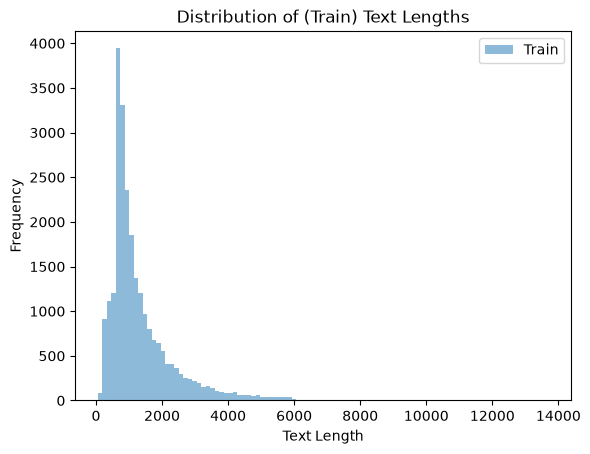

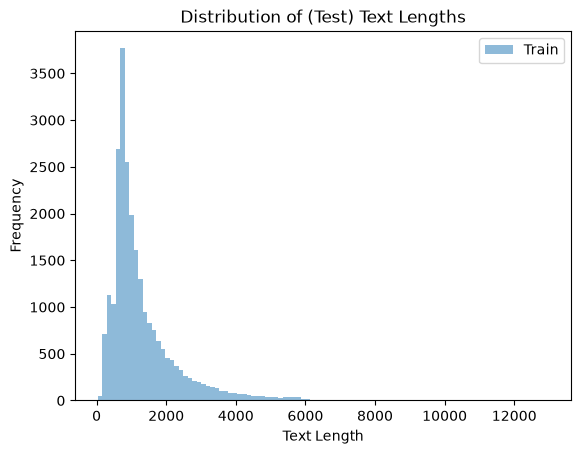

In [5]:
import matplotlib.pyplot as plt

plt.hist([len(text) for text in df_train['text']], bins=100, alpha=0.5, label='Train')
plt.xlabel('Text Length')
plt.ylabel('Frequency')
plt.title('Distribution of (Train) Text Lengths')
plt.legend()
plt.show()

plt.hist([len(text) for text in df_test['text']], bins=100, alpha=0.5, label='Train')
plt.xlabel('Text Length')
plt.ylabel('Frequency')
plt.title('Distribution of (Test) Text Lengths')
plt.legend()
plt.show()


The dataset is divided into a train set of 24904 rows and a test set of 24678 rows. Each row contains four columns: the review text, a label (0 for negative, 1 for positive), a label_text (negative or positive) and split (train or test). Both sets are almost equally balanced: the training set consists of 12472 positive (50.08%) and 12432 negative (50.02%) reviews, while the test set contains 12412 positive (50.30%) and 12266 negative (49.70%) reviews. Because the classes are evenly distributed, accuracy can be used as an evaluation metric for this analysis.

## Tokenizer

In [6]:
# I used the same parameteres as the tutorial used in the AG news example
tokenizer = Tokenizer(BPE(unk_token="[UNK]"))
tokenizer.pre_tokenizer = Metaspace()
trainer = BpeTrainer(vocab_size=1000, min_frequency=2, special_tokens=["[UNK]"])
corpus = df_train['text'].tolist()
tokenizer.train_from_iterator(corpus, trainer)

sample_text = df_test["text"].iloc[0]
output = tokenizer.encode(sample_text)
print(sample_text)
print(output.tokens)
print(output.ids)

I love sci-fi and am willing to put up with a lot. Sci-fi movies/TV are usually underfunded, under-appreciated and misunderstood. I tried to like this, I really did, but it is to good TV sci-fi as Babylon 5 is to Star Trek (the original). Silly prosthetics, cheap cardboard sets, stilted dialogues, CG that doesn't match the background, and painfully one-dimensional characters cannot be overcome with a 'sci-fi' setting. (I'm sure there are those of you out there who think Babylon 5 is good sci-fi TV. It's not. It's clichéd and uninspiring.) While US viewers might like emotion and character development, sci-fi is a genre that does not take itself seriously (cf. Star Trek). It may treat important issues, yet not as a serious philosophy. It's really difficult to care about the characters here as they are not simply foolish, just missing a spark of life. Their actions and reactions are wooden and predictable, often painful to watch. The makers of Earth KNOW it's rubbish as they have to alway

# Text representation spaces

## Token indicators

In [7]:
class TokenIndicator:

    def __init__(self, tokenizer: Tokenizer):
        self.tokenizer = tokenizer
        
    def __len__(self) -> int:
        """Dimensionality of the representation space"""
        return len(self.tokenizer.get_vocab())

    def __call__(self, x: str) -> 'np.array':
        """Represent x as a D-dimensional vector of real numbers"""
        unique_token_ids = list(set(self.tokenizer.encode(x).ids))

        # A 0 vector with the same length as the vocabulary except in positions corresponding 
        # to tokens appearing in the document
        vector = np.zeros(len(self))
        vector[unique_token_ids] = 1
        return vector

In [8]:
indicator = TokenIndicator(tokenizer)
indicator_output = indicator(sample_text)

print(indicator_output.sum())
print(len(indicator_output))

261.0
1000


## Bag of Words

In [9]:
class BagOfWords:

    def __init__(self, tokenizer: Tokenizer):
        self.tokenizer = tokenizer
        
    def __len__(self) -> int:
        """Dimensionality of the representation space"""
        return len(self.tokenizer.get_vocab())

    def __call__(self, x: str) -> 'np.array':
        """Represent x as a D-dimensional vector of real numbers"""
        token_ids = self.tokenizer.encode(x).ids
        counts = Counter(token_ids)

        vector = np.zeros(len(self))
        for token_id, count in counts.items():
            vector[token_id] = float(count)
        return vector

In [10]:
bow = BagOfWords(tokenizer)
bow_output = bow(sample_text)

print(bow_output.sum())
print(len(bow_output))

513.0
1000


## Bag of Bigrams

In [11]:
class BagOfBigrams:

    def __init__(self, tokenizer):
        self.tokenizer = tokenizer
        self.vocab_size = tokenizer.get_vocab_size()
        
    def __len__(self) -> int:
        """Dimensionality of the representation space"""
        return self.vocab_size ** 2

    def __call__(self, x: str) -> sp.coo_matrix:
        """Represent x directly as a memory-efficient D-dimensional sparse matrix"""
        token_ids = self.tokenizer.encode(x).ids
        bi_grams = bigrams(token_ids)
        bigram_ids = [id1 * self.vocab_size + id2 for id1, id2 in bi_grams]
        counts = Counter(bigram_ids)
        cols = list(counts.keys())
        data = list(counts.values())
        rows = [0] * len(cols)

        sparse_vector = sp.coo_matrix(
            (data, (rows, cols)), 
            shape=(1, len(self)), 
            dtype=np.float32
        )
        return sparse_vector

In [12]:
bob = BagOfBigrams(tokenizer)
bob_output = bob(sample_text)

print(bob_output.sum())
print(bob_output.size)

512.0
460


## Loglin

In [13]:
train_data = list(zip(df_train['text'], df_train['label']))
encoders = [TokenIndicator, BagOfWords, BagOfBigrams]
for enc in encoders:
    encoder = enc(tokenizer)
    logistic_model = loglin.fit(train_data, encoder, save_to=None)
    logistic_predictions = loglin.predict(df_test['text'].tolist(), logistic_model, encoder)
    accuracy = accuracy_score(df_test['label'].tolist(), logistic_predictions)
    print(enc.__name__)
    print(accuracy)

c:\Users\alwin\anaconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:1457: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=-1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)
c:\Users\alwin\anaconda3\Lib\site-packages\sklearn\linear_model\_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(


TokenIndicator
0.8200421427992544


c:\Users\alwin\anaconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:1457: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=-1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)
c:\Users\alwin\anaconda3\Lib\site-packages\sklearn\linear_model\_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(


BagOfWords
0.8276197422805738


c:\Users\alwin\anaconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:1457: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=-1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)
c:\Users\alwin\anaconda3\Lib\site-packages\sklearn\linear_model\_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(


BagOfBigrams
0.8787584082988897


## Single-hidden layer MLP

In [14]:
import smlp
from sklearn.model_selection import train_test_split
from pathlib import Path
import torch
import experiment

device = "cuda" if torch.cuda.is_available() else "cpu"

In [15]:
train_data = list(zip(df_train['text'], df_train['label']))

k = 5

cross_validation_sets = experiment.cross_validation_split(
    pairs=train_data,
    k=k,
    seed=42
)

In [16]:
results_folder = Path("./results/cross_validation")
results_folder.mkdir(parents=True, exist_ok=True)

encoders = [
    TokenIndicator(tokenizer),
    BagOfWords(tokenizer),
    BagOfBigrams(tokenizer)
]

loglin_results = {}

for encoder in encoders:

    print(f"\nEncoder: {encoder.__class__.__name__}")

    results = experiment.cross_validation_experiment(
        data_splits=cross_validation_sets,
        outcome_space=[0, 1],
        encoder=encoder,
        model_option="logistic",
        save_to=str(results_folder / encoder.__class__.__name__)
    )

    loglin_results[encoder.__class__.__name__] = results

    accuracies = list(results["accuracies"].values())

    print("Fold accuracies:", accuracies)
    print(f"Mean accuracy: {np.mean(accuracies):.4f}")
    print(f"Standard deviation: {np.std(accuracies):.4f}")


Encoder: TokenIndicator


  0%|          | 0/5 [00:00<?, ?it/s]

c:\Users\alwin\anaconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:1457: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=-1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)
c:\Users\alwin\anaconda3\Lib\site-packages\sklearn\linear_model\_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
c:\Users\alwin\anaconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:1457: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=-1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)
c:\Users\alwin\anaconda3\Lib\site-packages\sklearn\linear_model\_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
c:\Users\alwin\anaconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:1457: FutureWarning: 'n_jobs' has no effect sin

Fold accuracies: [0.8277454326440474, 0.8193133908853644, 0.8225255972696246, 0.8245332262597872, 0.8240963855421687]
Mean accuracy: 0.8236
Standard deviation: 0.0028

Encoder: BagOfWords


  0%|          | 0/5 [00:00<?, ?it/s]

c:\Users\alwin\anaconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:1457: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=-1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)
c:\Users\alwin\anaconda3\Lib\site-packages\sklearn\linear_model\_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
c:\Users\alwin\anaconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:1457: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=-1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)
c:\Users\alwin\anaconda3\Lib\site-packages\sklearn\linear_model\_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
c:\Users\alwin\anaconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:1457: FutureWarning: 'n_jobs' has no effect sin

Fold accuracies: [0.8401927323830556, 0.8301545874322426, 0.8245332262597872, 0.8201164424814295, 0.8253012048192772]
Mean accuracy: 0.8281
Standard deviation: 0.0069

Encoder: BagOfBigrams


  0%|          | 0/5 [00:00<?, ?it/s]

c:\Users\alwin\anaconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:1457: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=-1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)
c:\Users\alwin\anaconda3\Lib\site-packages\sklearn\linear_model\_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
c:\Users\alwin\anaconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:1457: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=-1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)
c:\Users\alwin\anaconda3\Lib\site-packages\sklearn\linear_model\_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
c:\Users\alwin\anaconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:1457: FutureWarning: 'n_jobs' has no effect sin

Fold accuracies: [0.8841598072676169, 0.8962055812085926, 0.8763300542059828, 0.8787392089941779, 0.8785140562248996]
Mean accuracy: 0.8828
Standard deviation: 0.0072


## MLP Cross-validation

In [17]:
mlp_results = {}

for encoder in encoders:

    print(f"\nEncoder: {encoder.__class__.__name__}")

    results = experiment.cross_validation_experiment(
        data_splits=cross_validation_sets,
        outcome_space=[0, 1],
        encoder=encoder,
        model_option="mlp",
        save_to=str(results_folder / f"MLP_{encoder.__class__.__name__}"),
        smlp_args={
            "hidden_dim": 128,
            "dropout": 0.1,
            "batch_size": 64,
            "learning_rate": 1e-4,
            "weight_decay": 1e-4,
            "num_epochs": 10,
            "device": device
        }
    )

    mlp_results[encoder.__class__.__name__] = results

    accuracies = list(results["accuracies"].values())

    print("Fold accuracies:", accuracies)
    print(f"Mean accuracy: {np.mean(accuracies):.4f}")
    print(f"Standard deviation: {np.std(accuracies):.4f}")


Encoder: TokenIndicator


  0%|          | 0/5 [00:00<?, ?it/s]

Transforming documents...
Document transformation done! Time taken: 16.596 seconds
Dataloader done! Time taken: 0.435 seconds
Training...


  0%|          | 0/10 [00:00<?, ?it/s]

c:\Users\alwin\Documents\Studie\Master\NLP1\NLP1_project\smlp.py:69: UserWarning: Creating a tensor from a list of numpy.ndarrays is extremely slow. Please consider converting the list to a single numpy.ndarray with numpy.array() before converting to a tensor. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\torch\csrc\utils\tensor_new.cpp:252.)
  indices = torch.tensor([x.row, x.col], dtype=torch.long)
c:\Users\alwin\Documents\Studie\Master\NLP1\NLP1_project\smlp.py:72: UserWarning: Sparse invariant checks are implicitly disabled. Memory errors (e.g. SEGFAULT) will occur when operating on a sparse tensor which violates the invariants, but checks incur performance overhead. To silence this warning, explicitly opt in or out. See `torch.sparse.check_sparse_tensor_invariants.__doc__` for guidance.  (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\aten\src\ATen\Context.cpp:923.)
  return torch.sparse_coo_tensor(indices, values, size=x.shape).coalesce()


Epoch 01 | train loss: 0.6115 | train acc: 0.6731 | val loss: 0.5097 | val acc: 0.7856
Epoch 02 | train loss: 0.4621 | train acc: 0.7995 | val loss: 0.4281 | val acc: 0.8165
Epoch 03 | train loss: 0.4116 | train acc: 0.8198 | val loss: 0.4054 | val acc: 0.8279
Epoch 04 | train loss: 0.3939 | train acc: 0.8306 | val loss: 0.4005 | val acc: 0.8261
Epoch 05 | train loss: 0.3825 | train acc: 0.8338 | val loss: 0.3928 | val acc: 0.8314
Epoch 06 | train loss: 0.3752 | train acc: 0.8367 | val loss: 0.3924 | val acc: 0.8310
Epoch 07 | train loss: 0.3714 | train acc: 0.8398 | val loss: 0.3932 | val acc: 0.8308
Epoch 08 | train loss: 0.3668 | train acc: 0.8412 | val loss: 0.3915 | val acc: 0.8332
Epoch 09 | train loss: 0.3612 | train acc: 0.8446 | val loss: 0.4011 | val acc: 0.8229
Epoch 10 | train loss: 0.3580 | train acc: 0.8455 | val loss: 0.3909 | val acc: 0.8308
Training done! Time taken: 79.909 seconds
Transforming documents...
Document transformation done! Time taken: 23.288 seconds
Datal

... (21 outputs left out)

Transforming documents...
Document transformation done! Time taken: 25.367 seconds
Dataloader done! Time taken: 2.233 seconds
Training...


  0%|          | 0/10 [00:00<?, ?it/s]

Epoch 01 | train loss: 0.4067 | train acc: 0.8557 | val loss: 0.2758 | val acc: 0.9050
Epoch 02 | train loss: 0.1275 | train acc: 0.9708 | val loss: 0.2388 | val acc: 0.9125


KeyboardInterrupt: 

In [ ]:
summary = []

for name, results in loglin_results.items():
    accuracies = list(results["accuracies"].values())

    summary.append({
        "Model": "Logistic Regression",
        "Encoder": name,
        "Mean accuracy": np.mean(accuracies),
        "Std": np.std(accuracies)
    })

for name, results in mlp_results.items():
    accuracies = list(results["accuracies"].values())

    summary.append({
        "Model": "MLP",
        "Encoder": name,
        "Mean accuracy": np.mean(accuracies),
        "Std": np.std(accuracies)
    })

results_df = pd.DataFrame(summary)

results_df

## Train mlp on entire dataset and test on test set

In [ ]:
# Use half of test set for validation and other galf for testing
train_data = list(zip(df_train['text'], df_train['label']))
test_data = list(zip(df_test['text'], df_test['label']))

validation_set, test_set = train_test_split(
    test_data,
    test_size=0.5,
    random_state=42,
    stratify=df_test['label']
)

In [ ]:
# save models and outputs there to keep the directory tree organised
results_folder = Path("./results")
results_folder.mkdir(parents=True, exist_ok=True) 
results_folder

WindowsPath('results')

In [ ]:
encoders = [TokenIndicator(tokenizer), BagOfWords(tokenizer), BagOfBigrams(tokenizer)]

for encoder in encoders:
    print(f"\nTraining with encoder: {encoder.__class__.__name__}")
    # Same parameters as the tutorial
    metrics, best_epoch, predictions = smlp.train_neural_network_model(
        training_set=train_data,
        validation_set=validation_set,
        num_classes=2,
        encoder=encoder,
        save_to=f'{results_folder}/{encoder.__class__.__name__}',
        hidden_dim=128,
        dropout=0.1,
        batch_size=64,
        learning_rate=1e-4,
        weight_decay=1e-4,
        num_epochs=10,
        device=device
    )


Training with encoder: TokenIndicator
Transforming documents...
Document transformation done! Time taken: 23.507 seconds
Dataloader done! Time taken: 0.582 seconds
Training...


  0%|          | 0/10 [00:00<?, ?it/s]

c:\Users\alwin\Documents\Studie\Master\NLP1\NLP1_project\smlp.py:69: UserWarning: Creating a tensor from a list of numpy.ndarrays is extremely slow. Please consider converting the list to a single numpy.ndarray with numpy.array() before converting to a tensor. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\torch\csrc\utils\tensor_new.cpp:252.)
  indices = torch.tensor([x.row, x.col], dtype=torch.long)
c:\Users\alwin\Documents\Studie\Master\NLP1\NLP1_project\smlp.py:72: UserWarning: Sparse invariant checks are implicitly disabled. Memory errors (e.g. SEGFAULT) will occur when operating on a sparse tensor which violates the invariants, but checks incur performance overhead. To silence this warning, explicitly opt in or out. See `torch.sparse.check_sparse_tensor_invariants.__doc__` for guidance.  (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\aten\src\ATen\Context.cpp:923.)
  return torch.sparse_coo_tensor(indices, values, size=x.shape).coalesce()


Epoch 01 | train loss: 0.5955 | train acc: 0.6917 | val loss: 0.4842 | val acc: 0.7965
Epoch 02 | train loss: 0.4424 | train acc: 0.8081 | val loss: 0.4124 | val acc: 0.8190
Epoch 03 | train loss: 0.4004 | train acc: 0.8273 | val loss: 0.3990 | val acc: 0.8266
Epoch 04 | train loss: 0.3863 | train acc: 0.8345 | val loss: 0.3918 | val acc: 0.8287
Epoch 05 | train loss: 0.3789 | train acc: 0.8375 | val loss: 0.3923 | val acc: 0.8269
Epoch 06 | train loss: 0.3706 | train acc: 0.8397 | val loss: 0.3955 | val acc: 0.8279
Epoch 07 | train loss: 0.3637 | train acc: 0.8438 | val loss: 0.3910 | val acc: 0.8265
Epoch 08 | train loss: 0.3587 | train acc: 0.8456 | val loss: 0.3906 | val acc: 0.8245
Epoch 09 | train loss: 0.3544 | train acc: 0.8494 | val loss: 0.3909 | val acc: 0.8264
Epoch 10 | train loss: 0.3480 | train acc: 0.8506 | val loss: 0.3915 | val acc: 0.8266
Training done! Time taken: 93.688 seconds

Training with encoder: BagOfWords
Transforming documents...
Document transformation don

  0%|          | 0/10 [00:00<?, ?it/s]

Epoch 01 | train loss: 0.6001 | train acc: 0.6841 | val loss: 0.4906 | val acc: 0.7984
Epoch 02 | train loss: 0.4577 | train acc: 0.8064 | val loss: 0.4374 | val acc: 0.8185
Epoch 03 | train loss: 0.4136 | train acc: 0.8271 | val loss: 0.4181 | val acc: 0.8272
Epoch 04 | train loss: 0.3924 | train acc: 0.8374 | val loss: 0.4061 | val acc: 0.8300
Epoch 05 | train loss: 0.3777 | train acc: 0.8416 | val loss: 0.4007 | val acc: 0.8333
Epoch 06 | train loss: 0.3649 | train acc: 0.8499 | val loss: 0.3974 | val acc: 0.8316
Epoch 07 | train loss: 0.3547 | train acc: 0.8525 | val loss: 0.3965 | val acc: 0.8330
Epoch 08 | train loss: 0.3457 | train acc: 0.8574 | val loss: 0.3935 | val acc: 0.8332
Epoch 09 | train loss: 0.3354 | train acc: 0.8613 | val loss: 0.3919 | val acc: 0.8363
Epoch 10 | train loss: 0.3269 | train acc: 0.8629 | val loss: 0.3906 | val acc: 0.8358
Training done! Time taken: 102.302 seconds

Training with encoder: BagOfBigrams
Transforming documents...
Document transformation 

  0%|          | 0/10 [00:00<?, ?it/s]

Epoch 01 | train loss: 0.3734 | train acc: 0.8705 | val loss: 0.2815 | val acc: 0.9010
Epoch 02 | train loss: 0.1097 | train acc: 0.9757 | val loss: 0.2587 | val acc: 0.9051
Epoch 03 | train loss: 0.0386 | train acc: 0.9959 | val loss: 0.2700 | val acc: 0.9023
Epoch 04 | train loss: 0.0163 | train acc: 0.9995 | val loss: 0.2832 | val acc: 0.9029
Epoch 05 | train loss: 0.0086 | train acc: 0.9998 | val loss: 0.2989 | val acc: 0.9008
Epoch 06 | train loss: 0.0051 | train acc: 0.9998 | val loss: 0.3129 | val acc: 0.9006
Epoch 07 | train loss: 0.0033 | train acc: 0.9999 | val loss: 0.3258 | val acc: 0.9009
Epoch 08 | train loss: 0.0023 | train acc: 0.9999 | val loss: 0.3369 | val acc: 0.9010
Epoch 09 | train loss: 0.0016 | train acc: 0.9999 | val loss: 0.3480 | val acc: 0.9006
Epoch 10 | train loss: 0.0012 | train acc: 0.9999 | val loss: 0.3593 | val acc: 0.9001
Training done! Time taken: 5625.734 seconds


In [ ]:
encoders = [TokenIndicator(tokenizer), BagOfWords(tokenizer), BagOfBigrams(tokenizer)]
for encoder in encoders:
    print(f"\nTesting for encoder: {encoder.__class__.__name__}")
    test_texts = [text for text, label in test_set]
    test_labels = [label for text, label in test_set]

    model = smlp.load(f'{results_folder}/{encoder.__class__.__name__}')

    test_probs = smlp.predict_probs(
        texts=test_texts,
        model=model,
        encoder=encoder
    )

    test_predictions = np.argmax(test_probs, axis=1)
    accuracy = accuracy_score(test_labels, test_predictions)
    print("SMLP test accuracy:", accuracy)


Testing for encoder: TokenIndicator


c:\Users\alwin\Documents\Studie\Master\NLP1\NLP1_project\smlp.py:69: UserWarning: Creating a tensor from a list of numpy.ndarrays is extremely slow. Please consider converting the list to a single numpy.ndarray with numpy.array() before converting to a tensor. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\torch\csrc\utils\tensor_new.cpp:252.)
  indices = torch.tensor([x.row, x.col], dtype=torch.long)
c:\Users\alwin\Documents\Studie\Master\NLP1\NLP1_project\smlp.py:72: UserWarning: Sparse invariant checks are implicitly disabled. Memory errors (e.g. SEGFAULT) will occur when operating on a sparse tensor which violates the invariants, but checks incur performance overhead. To silence this warning, explicitly opt in or out. See `torch.sparse.check_sparse_tensor_invariants.__doc__` for guidance.  (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\aten\src\ATen\Context.cpp:923.)
  return torch.sparse_coo_tensor(indices, values, size=x.shape).coalesce()


SMLP test accuracy: 0.8178134370694545

Testing for encoder: BagOfWords
SMLP test accuracy: 0.8288353999513737

Testing for encoder: BagOfBigrams
SMLP test accuracy: 0.8981278871869681


Using the tutorial's analysis.BenavoliCorrelatedT


/tmp/ipykernel_10494/3913635666.py:86: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  ax.boxplot([all_acc[n] for n in names], vert=False)  # if your matplotlib warns: orientation="horizontal"


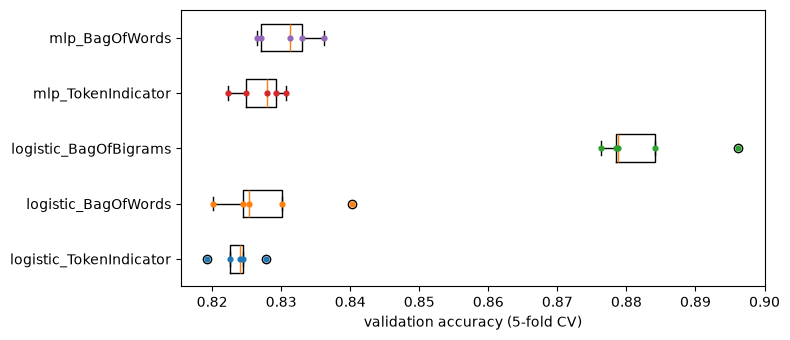

A=logistic_TokenIndicator B=mlp_TokenIndicator: P(A wins)=0.0005 P(Tie)=0.9929 P(B wins)=0.0066 Effect size=2.20


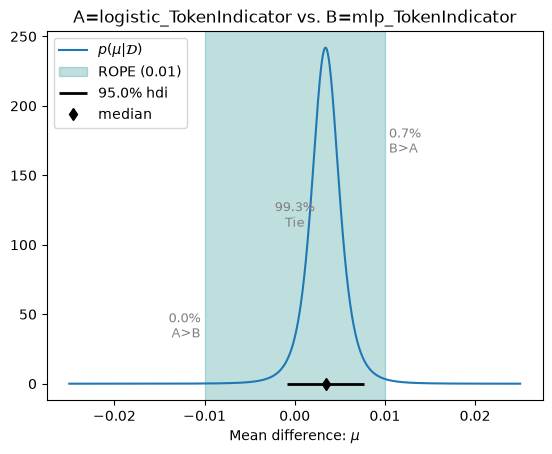

                      A                     B  mean A-B  P(A wins)  P(Tie)  P(B wins) verdict
logistic_TokenIndicator   logistic_BagOfWords   -0.0044     0.0192  0.8286     0.1522 unclear
logistic_TokenIndicator logistic_BagOfBigrams   -0.0591     0.0002  0.0007     0.9991       B
logistic_TokenIndicator    mlp_TokenIndicator   -0.0034     0.0005  0.9929     0.0066     tie
logistic_TokenIndicator        mlp_BagOfWords   -0.0072     0.0020  0.8050     0.1930 unclear
    logistic_BagOfWords logistic_BagOfBigrams   -0.0547     0.0002  0.0005     0.9994       B
    logistic_BagOfWords    mlp_TokenIndicator    0.0010     0.0631  0.8980     0.0389 unclear
    logistic_BagOfWords        mlp_BagOfWords   -0.0028     0.0059  0.9601     0.0340     tie
  logistic_BagOfBigrams    mlp_TokenIndicator    0.0557     0.9992  0.0006     0.0002       A
  logistic_BagOfBigrams        mlp_BagOfWords    0.0520     0.9997  0.0003     0.0001       A
     mlp_TokenIndicator        mlp_BagOfWords   -0.0038     

In [ ]:
# Standalone ROPE analysis: runs in a fresh kernel, no earlier cells needed.
# Bayesian correlated t-test (Benavoli et al. 2017), as in the tutorial.

import json
from itertools import combinations
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

# 1. Data: fold accuracies copied from the printed outputs of the CV cells
# (one seed, 5 folds, same cross_validation_sets for every system).
# MLP + BagOfBigrams is missing: its CV run was interrupted.
# All models here: (5 fold accuracies each, same folds).
NUM_FOLDS = 5
all_acc = {
    "logistic_TokenIndicator": [0.8277454326440474, 0.8193133908853644, 0.8225255972696246, 0.8245332262597872, 0.8240963855421687],
    "logistic_BagOfWords":     [0.8401927323830556, 0.8301545874322426, 0.8245332262597872, 0.8201164424814295, 0.8253012048192772],
    "logistic_BagOfBigrams":   [0.8841598072676169, 0.8962055812085926, 0.8763300542059828, 0.8787392089941779, 0.8785140562248996],
    "mlp_TokenIndicator":      [0.8307568761292913, 0.8249347520578197, 0.8223248343706083, 0.8279461955430636, 0.8293172690763052],
    "mlp_BagOfWords":          [0.8361774744027304, 0.8329652680184702, 0.8265408552499498, 0.8271431439469986, 0.8313253012048193],
}

Path("results").mkdir(exist_ok=True)
json.dump(all_acc, open("results/cv_accuracies.json", "w"), indent=2)

# ROPE: 1 accuracy point. Below that we would not prefer one system over another
# (about 50 of ~5,000 reviews per fold). The tutorial used 0.005 on AG News.
ROPE = 0.01

# 2. Correlated t-test. Uses the tutorial's analysis.py
# otherwise the same model written out here (copied it).
try:
    import analysis
    CorrelatedT = analysis.BenavoliCorrelatedT
    print("Using the tutorial's analysis.BenavoliCorrelatedT")
except ImportError:
    class CorrelatedT:
        """Posterior over the mean accuracy difference A - B.

        Per-fold differences d_i ~ Normal(mu, sigma^2), with correlation rho = 1/k between
        folds (training sets overlap in k-fold CV). With the usual flat prior, the posterior
        of mu is a Student-t with n-1 degrees of freedom, centred on mean(d), with scale
        sqrt((1/n + rho/(1-rho)) * var(d)).
        """
        def __init__(self, acc_a, acc_b, names=("A", "B"), num_folds=NUM_FOLDS):
            d = np.asarray(acc_a) - np.asarray(acc_b)
            n = len(d)
            rho = 1.0 / num_folds
            var = d.var(ddof=1)
            self.names = names
            self.mean = d.mean()
            self.scale = np.sqrt((1.0 / n + rho / (1.0 - rho)) * var)
            self.dist = stats.t(df=n - 1, loc=self.mean, scale=self.scale)
            self.effect_size = self.mean / np.sqrt(var) if var > 0 else np.inf

        def probs(self, rope):
            p_b = self.dist.cdf(-rope)          # A - B < -rope  -> B better
            p_a = 1.0 - self.dist.cdf(rope)     # A - B >  rope  -> A better
            return p_a, 1.0 - p_a - p_b, p_b

        def plot(self, rope, ax=None):
            ax = ax or plt.subplots(figsize=(6, 3))[1]
            lo = min(self.dist.ppf(0.001), -2 * rope)
            hi = max(self.dist.ppf(0.999), 2 * rope)
            x = np.linspace(lo, hi, 500)
            ax.plot(x, self.dist.pdf(x))
            ax.axvspan(-rope, rope, alpha=0.2, color="gray", label=f"ROPE ±{rope}")
            ax.set_xlabel(f"mean accuracy difference ({self.names[0]} - {self.names[1]})")
            ax.set_yticks([])
            ax.legend()
            return ax
    print("analysis.py not found: using the built-in correlated t-test")


# Look at raw fold accuracies
fig, ax = plt.subplots(figsize=(8, 3.5))
names = list(all_acc)
ax.boxplot([all_acc[n] for n in names], vert=False)
for i, n in enumerate(names, start=1):
    ax.scatter(all_acc[n], [i] * len(all_acc[n]), s=12, zorder=3)
ax.set_yticks(range(1, len(names) + 1), names)
ax.set_xlabel("validation accuracy (5-fold CV)")
plt.tight_layout()
plt.show()

# One pair in detail, with plot (just like in the tutorial).
a, b = "logistic_TokenIndicator", "mlp_TokenIndicator"
post = CorrelatedT(all_acc[a], all_acc[b], names=[a, b])
p_a, p_tie, p_b = post.probs(ROPE)
print(f"A={a} B={b}: P(A wins)={p_a:.4f} P(Tie)={p_tie:.4f} P(B wins)={p_b:.4f} Effect size={post.effect_size:.2f}")
post.plot(ROPE)
plt.show()

# 5. All pairs
def compare_all_pairs(acc, rope):
    rows = []
    for a, b in combinations(acc, 2):
        post = CorrelatedT(acc[a], acc[b], names=[a, b])
        p_a, p_tie, p_b = post.probs(rope)
        rows.append({
            "A": a, "B": b,
            "mean A-B": np.mean(acc[a]) - np.mean(acc[b]),
            "P(A wins)": p_a, "P(Tie)": p_tie, "P(B wins)": p_b,
            "verdict": "A" if p_a > 0.95 else "B" if p_b > 0.95 else "tie" if p_tie > 0.95 else "unclear",
        })
    return pd.DataFrame(rows)

rope_table = compare_all_pairs(all_acc, ROPE)
print(rope_table.round(4).to_string(index=False))

# Does the conclusion depend on the ROPE size?
for r in [0.005, 0.01, 0.02]:
    print(f"ROPE={r}:", compare_all_pairs(all_acc, r)["verdict"].value_counts().to_dict())

### Results of the Bayesian analysis

We compared every pair of systems with the Bayesian correlated t-test (Benavoli et al., 2017), using the 5 fold accuracies of each system. For each pair, the test gives a posterior over the mean accuracy difference. We then look at how much of that posterior falls inside the ROPE of ±0.01 (1 accuracy point), which we treat as "no practical difference". A pair counts as decided when one of the three outcomes (A better, tie, B better) gets more than 95% of the probability.

Bigrams clearly help. Log-linear with bag-of-bigrams beats every other system by about 5 to 6 accuracy points, with P(win) ≈ 0.999 in every comparison. It is the only representation that captures some word order (for example "not good"), which matters for sentiment. The hidden layer does not help on unigram features. also Indicators vs counts makes little difference. Some pairs stay unclear (P(tie) between 0.8 and 0.9). The differences are small, but with only 5 folds and one seed there isn't enough data to place them firmly inside the ROPE. The ROPE size matters for the close pairs. At ±0.005 (the tutorial's value), six pairs are unclear. At ±0.02, all six close pairs are ties. The bigram results don't change at any of these sizes. So the conclusion "bigrams win" holds up, while "the rest are equal" depends on what we accept as a practically irrelevant difference.

*Note: the bigram MLP and the third architecture are not included yet. Their CV runs still need to finish.*